# 🌍 Phase 2: Exploratory Data Analysis (EDA)

Welcome to the **Exploration Phase**.
In this notebook, we transform the rigorously cleaned data into a narrative, discovering patterns, anomalies, and insights.

**Key Goals:**
1.  **Univariate Analysis**: Understand the distribution of scores, popularity, and episodes (Normality vs Power Laws).
2.  **Bivariate Analysis**: Uncover correlations (Does popularity equal quality?).
3.  **Outlier Detection**: Find the "Masterpieces" ($Z > 3\sigma$) and the "Infinite Series" (IQR Outliers).
4.  **Controversy Metric**: Identify anime with high voting variance (Love/Hate).
5.  **Geospatial**: Quick look at user demographics.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 🔧 Dynamic Path Setup (Fixes ModuleNotFoundError)
# We need to access 'solution' package from standard path
current_dir = Path(os.getcwd())
project_root = current_dir.parent.parent # solution/notebooks -> solution -> root
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 📦 Import Project Modules
from nb_02_exploration import (
    load_data,
    calculate_controversy_metric,
    identify_outliers_iqr,
    identify_outliers_zscore,
    setup_style,
    plot_distribution,
    plot_correlation_matrix,
    plot_categorical_comparison,
    generate_user_map
)

# Setup Visuals
setup_style()

## 1. Load Data
We load the **optimized Parquet files** from `data/processed` using `pyarrow` engine.

In [2]:
df_details = load_data("details")
df_stats = load_data("stats")
df_profiles = load_data("profiles")

print(f"Details Shape: {df_details.shape}")
print(f"Stats Shape:   {df_stats.shape}")
print(f"Profiles Shape: {df_profiles.shape}")

# Merge important details into stats for correlation analysis
# We likely want score, favorites, members from stats, and type, episodes from details
df_merged = df_details[
    ['mal_id', 'title', 'type', 'source', 'episodes', 'rating', 'score', 'scored_by', 'rank', 'popularity', 'members', 'favorites']
].merge(
    df_stats[['mal_id', 'watching', 'completed']], 
    on='mal_id',
    how='inner'
)
print(f"Merged Dataset Shape: {df_merged.shape}")

Loading C:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\data\processed\details.parquet...
Loading C:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\data\processed\stats.parquet...
Loading C:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\data\processed\profiles.parquet...
Details Shape: (28955, 29)
Stats Shape:   (28955, 27)
Profiles Shape: (337155, 10)
Merged Dataset Shape: (28955, 14)


## 2. Univariate Analysis
### A. Score Distribution (Normality)
Does the scoring follow a Bell Curve? Or is there a bias?

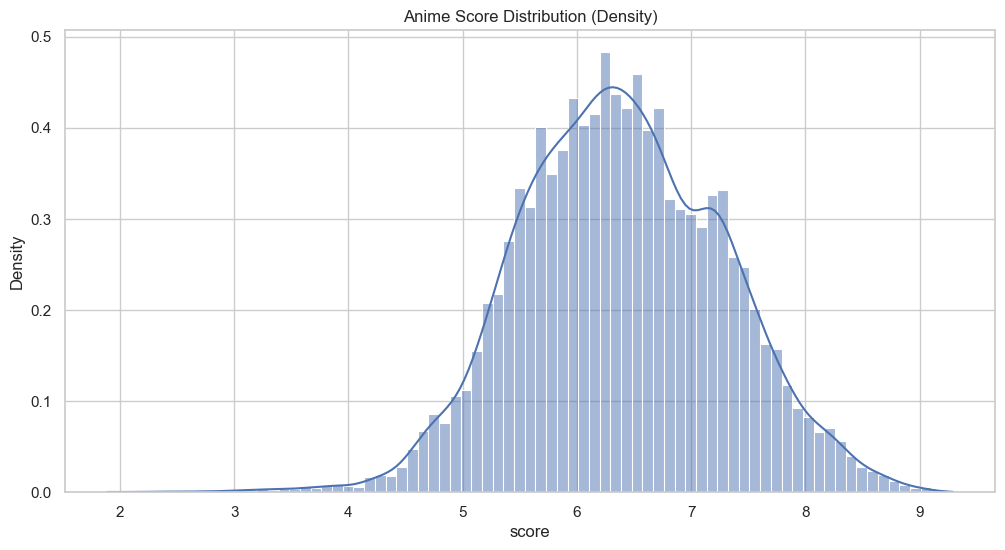

In [3]:
plot_distribution(df_merged, 'score', title="Anime Score Distribution (Density)")

### B. Popularity (The Long Tail)
Checking metrics like `members` or `scored_by`. We expect a Power Law (Zipfian) distribution.
We check this by applying a Log Scale.

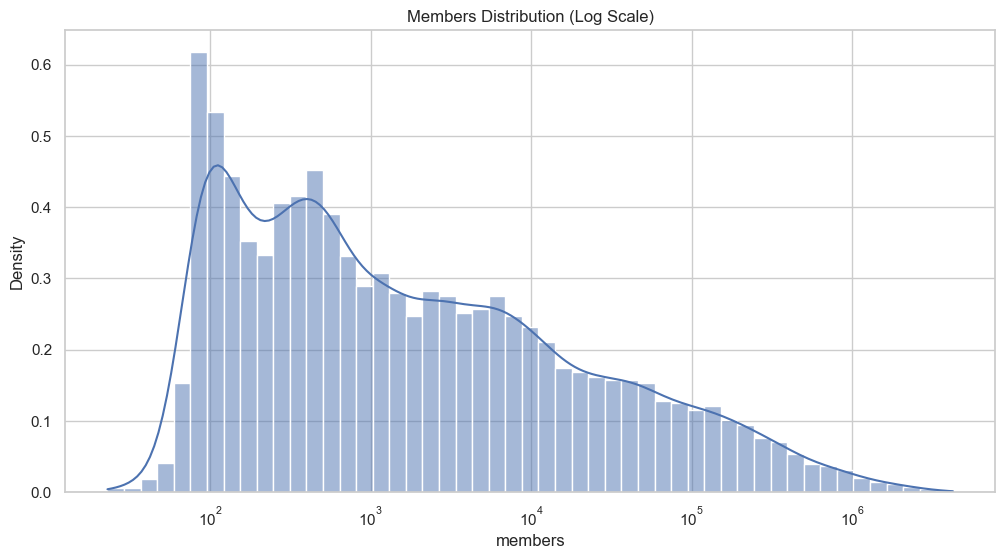

c:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


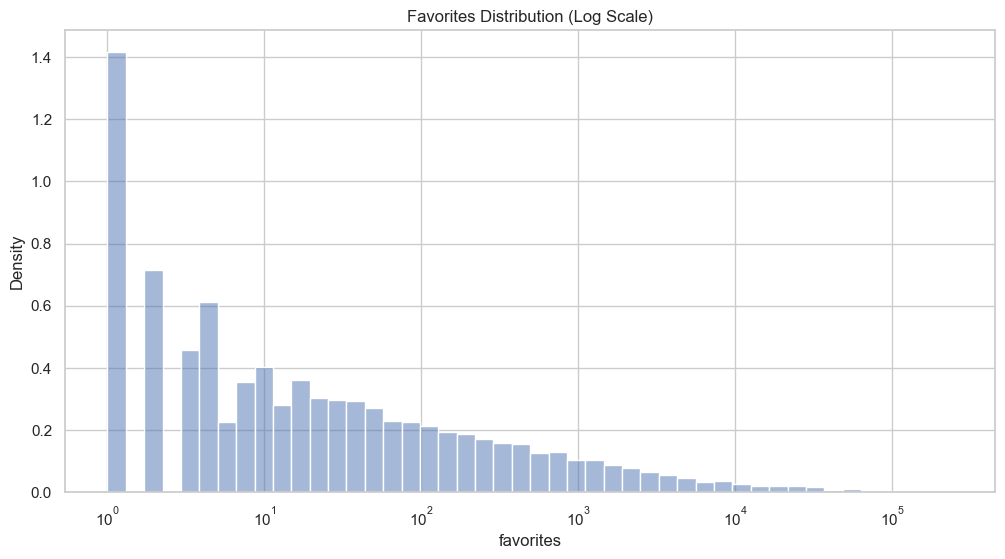

In [4]:
plot_distribution(df_merged, 'members', log_scale=True, title="Members Distribution (Log Scale)")
plot_distribution(df_merged, 'favorites', log_scale=True, title="Favorites Distribution (Log Scale)")

## 3. Bivariate Analysis
### A. Correlation Matrix
Does popularity (`members`) correlate with quality (`score`)?

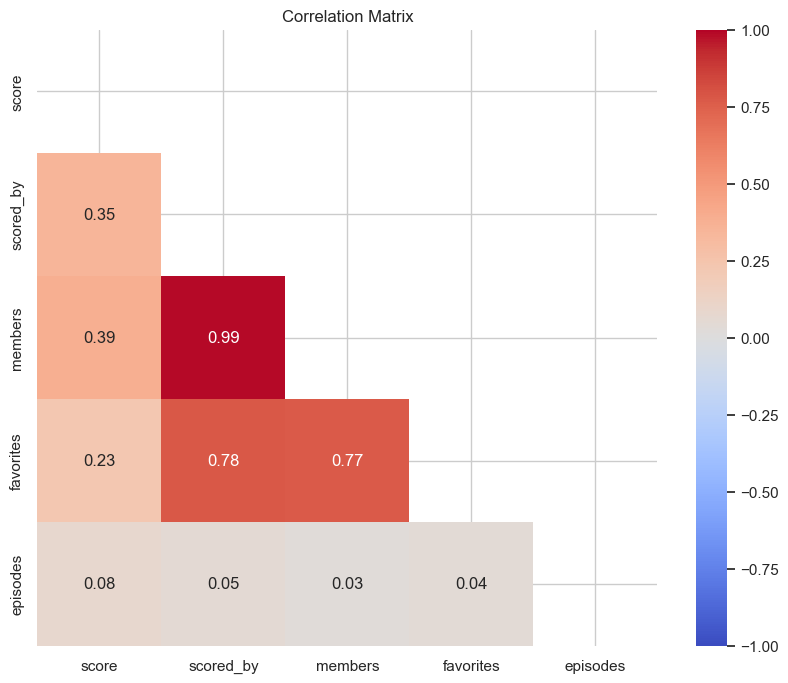

In [5]:
cols_to_corr = ['score', 'scored_by', 'members', 'favorites', 'episodes']
plot_correlation_matrix(df_merged, columns=cols_to_corr)

### B. Categorical Comparisons
Do 'Movies' perform better than 'TV' series? Does source material matter?

c:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\solution\notebooks\nb_02_exploration\plotting.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = data_to_plot.groupby(cat_col)[num_col].median().sort_values(ascending=False).index


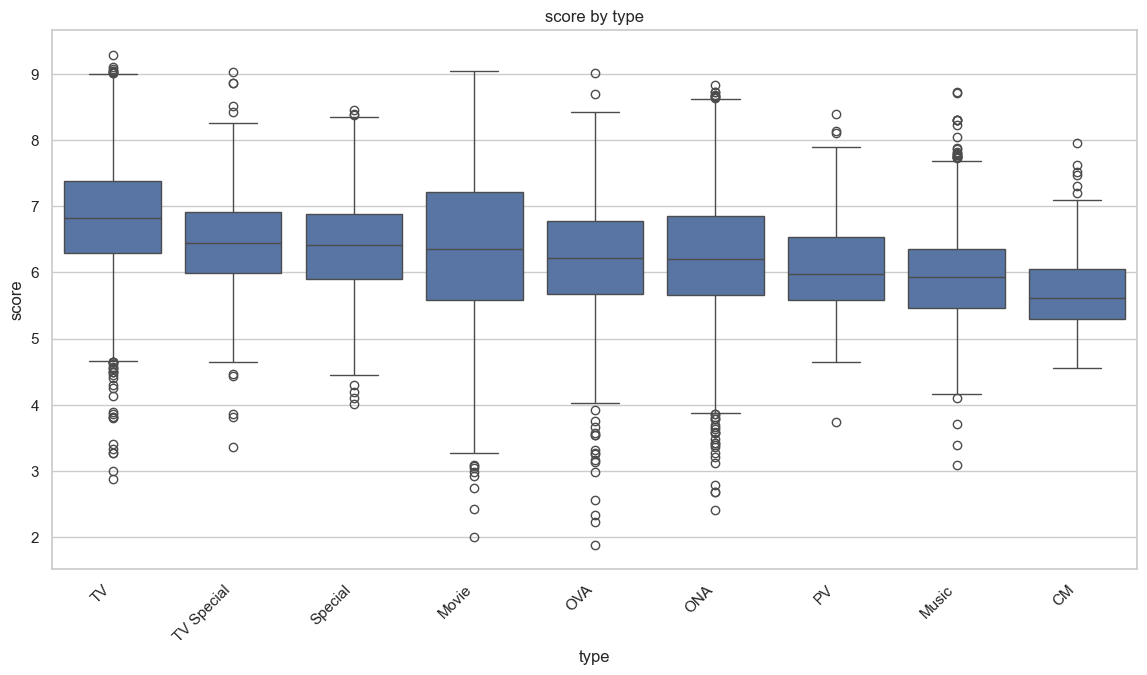

c:\Users\user\OneDrive\Desktop\IUM\Ciravegna\unito-hci-data-analysis-25-26\solution\notebooks\nb_02_exploration\plotting.py:66: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = data_to_plot.groupby(cat_col)[num_col].median().sort_values(ascending=False).index


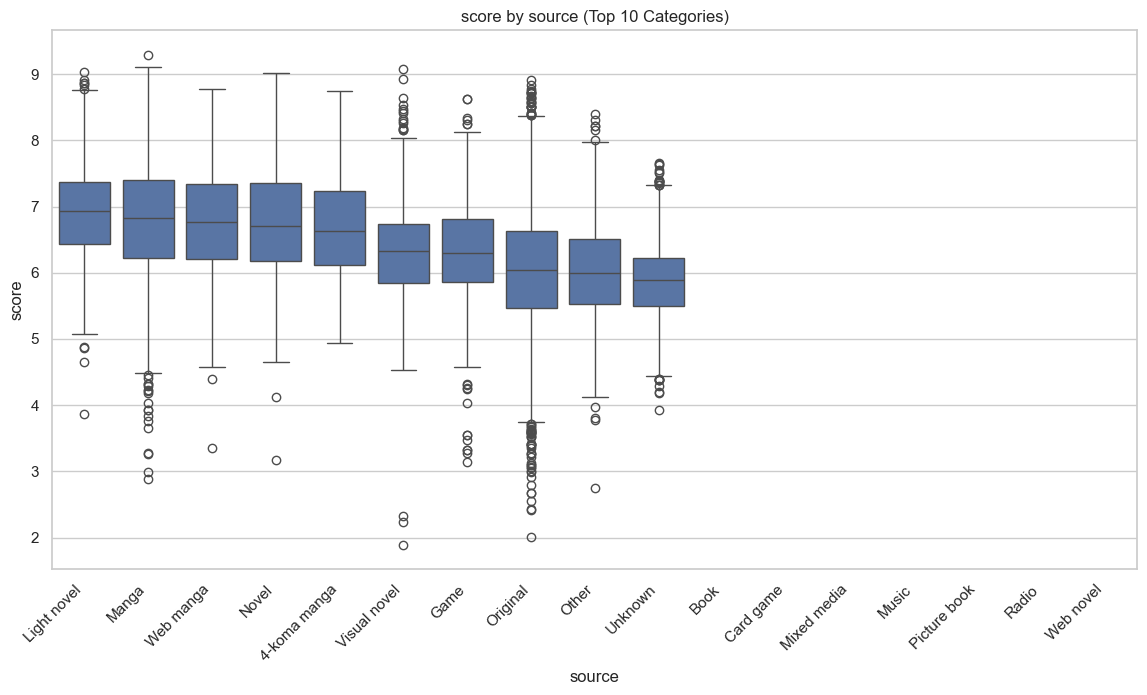

In [6]:
plot_categorical_comparison(df_merged, 'type', 'score')
plot_categorical_comparison(df_merged, 'source', 'score', top_n=10)

## 4. Outlier Detection
### A. Infinite Series (IQR on Episodes)
Identifying shows that run forever.

In [7]:
outliers_ep, low, high = identify_outliers_iqr(df_merged, 'episodes')
print(f"\nTop 10 Longest Running Anime:")
display(outliers_ep[['title', 'episodes', 'type']].sort_values('episodes', ascending=False).head(10))

IQR Outliers for 'episodes': found 3035 (Bounds: -17.00, 31.00)

Top 10 Longest Running Anime:


,title,episodes,type
13697,Lan Mao,3000.0,TV
18525,Oyako Club,1818.0,TV
5259,Doraemon (1979),1787.0,TV
7808,Gudetama,1717.0,TV
4660,Daomei Xiansheng,1664.0,TV
12550,Kirin Monoshiri Yakata,1565.0,TV
14913,Manga Nippon Mukashibanashi (1976),1471.0,TV
9245,Hokahoka Kazoku,1428.0,TV
12547,Kirin Ashita no Calendar,1306.0,TV
16157,Monoshiri Daigaku: Ashita no Calendar,1274.0,TV


### B. Statistical Masterpieces (Z-Score > 3)
Anime distinctively superior to the rest.

In [8]:
outliers_score = identify_outliers_zscore(df_merged, 'score', threshold=3.0)
print(f"\nTop Masterpieces (Z > 3):")
display(outliers_score[['title', 'score', 'rank', 'zscore']].sort_values('score', ascending=False))

Z-Score Outliers for 'score': found 64 (Threshold: 3.0 sigma)

Top Masterpieces (Z > 3):


,title,score,rank,zscore
23116,Sousou no Frieren,9.29,1.0,3.250484
6593,Fullmetal Alchemist: Brotherhood,9.10,2.0,3.037485
23288,Steins;Gate,9.07,3.0,3.003852
11626,Kanojo no Dokushinsha-tachi ni Yotte Hadaka ni...,3.71,14269.0,-3.004974
23930,Tama Gura Abayo: Moki Yumokyu Superdeluxe,3.71,NaN,-3.004974
...,...,...,...,...
12885,Kokuhaku,2.41,14321.0,-4.462338
25364,Tsui no Sora,2.33,NaN,-4.552023
8219,Hametsu no Mars,2.23,14322.0,-4.664128
26063,Utsu Musume Sayuri,2.01,14323.0,-4.910758


## 5. Controversy Analysis
Using weighted standard deviation on vote counts to find polarizing shows.
High SD = Mixed Reception (Love/Hate).
Low SD = Consensus.

In [9]:
# Requires full stats dataframe with vote columns
df_controversy = calculate_controversy_metric(df_stats)

# Merge title back for display
df_controversy = df_controversy.merge(
    df_details[['mal_id', 'title', 'scored_by', 'score']], 
    on='mal_id', 
    how='inner'
)

# Filter for relevant number of votes to avoid noise
print("Most Controversial Anime (High Vote Variance):")
complex_view = df_controversy[df_controversy['scored_by'] > 1000].sort_values('controversy_std', ascending=False)
display(complex_view[['title', 'score', 'controversy_std', 'scored_by']].head(10))

Calculating controversy metric (weighted deviation)...
Most Controversial Anime (High Vote Variance):


,title,score,controversy_std,scored_by
2673,Boku no Pico,4.21,3.559465,124183.0
18916,Pico x CoCo x Chico,4.34,3.351024,42845.0
3576,Chicken Papa,4.21,3.343385,2024.0
18915,Pico to Chico,4.35,3.314844,46180.0
18862,Petting a Dog,4.71,3.313511,1861.0
3459,Chargeman Ken!,4.49,3.210027,1791.0
17907,Onara Gorou,5.54,3.040015,7734.0
7856,Gun-dou Musashi,5.43,3.030986,1396.0
3078,Byston Well Monogatari: Garzey no Tsubasa,4.12,3.016364,6997.0
18944,Pingu in the City (2018),6.41,3.003716,5167.0


## 6. Geospatial Analysis
Where are the users coming from?

In [10]:
generate_user_map(df_profiles)

Generating location summary...
Top 20 User Locations:
location
Japan             98316
United States     65240
Germany           26348
United Kingdom    19520
Thailand          16416
Argentina         13230
China             13196
Spain             12916
France            10041
Australia          9691
Mexico             6634
South Korea        6524
Turkey             6516
Italy              6468
Indonesia          3334
Brazil             3293
Vietnam            3272
South Africa       3267
Philippines        3260
Egypt              3239
Name: count, dtype: int64
Missing locations: 0


location
Japan             98316
United States     65240
Germany           26348
United Kingdom    19520
Thailand          16416
Argentina         13230
China             13196
Spain             12916
France            10041
Australia          9691
Mexico             6634
South Korea        6524
Turkey             6516
Italy              6468
Indonesia          3334
Brazil             3293
Vietnam            3272
South Africa       3267
Philippines        3260
Egypt              3239
Name: count, dtype: int64